## PCA and Text Analysis

This assignment involves processing real e-mails, some of which are scams. 

(Fair warning: Some of these scam e-mails have offensive content. If you start reading the e-mail text or the token data, you might read something offensive. If that's a problem, feel free to e-mail us, and we can talk about it and discuss how to proceed with alternative tasks.)

**Q1.**

**Tokens**: The individual words or symbols that create text data like emails. Natural Language Processing is primarily about analyzing the frequency and co-occurrence of tokens.

We aggregated all the emails into a single vector, and removed the punctuation and very common words (e.g. "the"). Run the below code chunk to open it, and use the Counter class to look at the most common words:

In [8]:
import pickle
from collections import Counter
import matplotlib.pyplot as plt

Plot a histogram of the occurrences of tokens. 
What do you notice about the frequency of occurrence of different tokens? How does it look?

**Q2.** 

Load `Phishing_clean.parquet`. This is the text from the e-mails broken into the most common 2,711 tokens and one-hot-encoded as features/covariates. So each row is an e-mail, the `Email Type` takes the value 1 if it's a scam and 0 otherwise, and every other column is a word or symbol that occurs in at least 15 e-mails.

1. Perform an 80/20 train-test split of the data.
2. Run a regression of $y$ on the one-hot-encoded emails. What is the $R^2$ on the test set? On the training set?
3. What words have the largest coefficients in absolute value and most strongly influence predictions? 

**Q3.** 

Take the matrix of one-hot-encoded tokens (the data, less the outcome variable, `Email Type`) and perform a principal components analysis decomposition with two components. Plot the first two principal components in a scatter plot, and hue the points by whether they are a phishing scam or not. Do you notice any patterns?

**Q4.**

Run a linear regression of $y$ on the first 2,610 principal components of $X$. What is the $R^2$ on the training and test sets?
How does this performance compare to the linear regression?

**Q5.**

Explain briefly in your own words what the advantage is in using the principal components to run this high-dimensional regression, rather than the original data.

---

## *Phase 1: Solution without AI

Complete all questions in the following cells without generative AI. Then commit and push the
notebook before beginning Phase 2.

**Declaration:** I completed this version without generative AI.

**Student(s):** Leyton Allen

**Date:** 10/20/2026

Q1

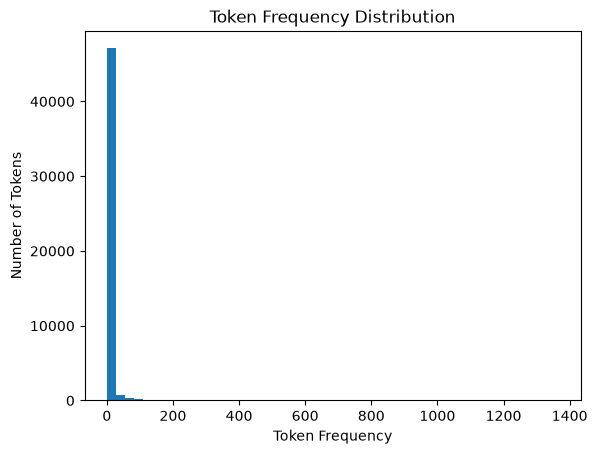

Most common tokens:
[('new', 1365), ('date', 1202), ('get', 1052), ('please', 1022), ('enron', 927), ('like', 923), ('2002', 869), ('would', 806), ('one', 798), ('message', 795)]


In [9]:
import pickle
from collections import Counter
import matplotlib.pyplot as plt

with open("data/all_tokens.pickle", "rb") as file:
    all_tokens = pickle.load(file)

token_count = Counter(all_tokens)
frequencies = list(token_count.values())

plt.hist(frequencies, bins=50)
plt.xlabel("Token Frequency")
plt.ylabel("Number of Tokens")
plt.title("Token Frequency Distribution")
plt.show()

print("Most common tokens:")
print(token_count.most_common(10))


Most tokens appear only a few times while a smaller number appear very frequently. This shows that some words are much more common than others.

Q2

In [ ]:
import pandas as pd
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression

df = pd.read_parquet("data/Phishing_clean.parquet")

X = df.drop(columns=["Email Type"])
y = df["Email Type"]

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)

model = LinearRegression()
model.fit(X_train, y_train)

print("Training R2:", model.score(X_train, y_train))
print("Testing R2:", model.score(X_test, y_test))

coefficients = pd.Series(model.coef_, index=X.columns)

top_words = coefficients.abs().sort_values(
    ascending=False
).head(10)

print("Top 10 most influential words:")
print(coefficients.loc[top_words.index])


I split the data into 80% training and 20% testing. The training R2 was 0.7670 and the testing R2 was 0.6659. The words with the largest absolute coefficients included intervention, localized, thermal, crawler, and background-image:. These words had the strongest influence on the model's predictions.

Q3

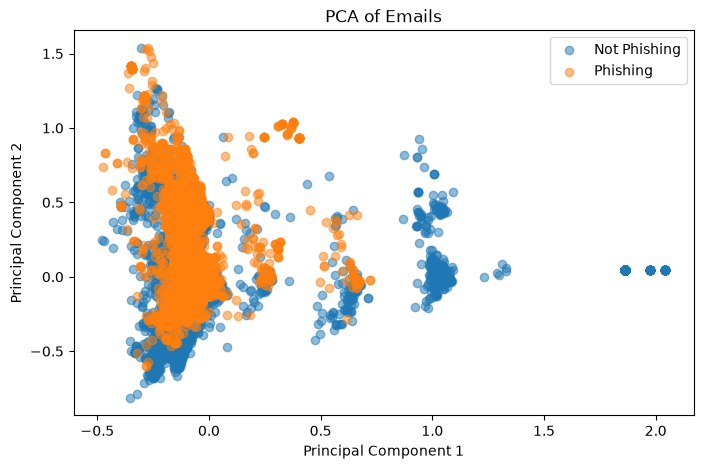

In [ ]:
from sklearn.decomposition import PCA

pca = PCA(n_components=2)
X_pca = pca.fit_transform(X)

plt.figure(figsize=(8, 5))

plt.scatter(
    X_pca[y == 0, 0],
    X_pca[y == 0, 1],
    label="Not Phishing",
    alpha=0.5
)

plt.scatter(
    X_pca[y == 1, 0],
    X_pca[y == 1, 1],
    label="Phishing",
    alpha=0.5
)

plt.xlabel("Principal Component 1")
plt.ylabel("Principal Component 2")
plt.title("PCA of Emails")
plt.legend()
plt.show()

The two groups overlap in the graph, so the first two principal components do not completely separate phishing emails from regular emails.

Q4

In [ ]:

pca = PCA(
    n_components=2610,
    svd_solver="randomized",
    random_state=42
)

X_train_pca = pca.fit_transform(X_train)
X_test_pca = pca.transform(X_test)

pca_model = LinearRegression()
pca_model.fit(X_train_pca, y_train)

print("PCA Training R2:",
      pca_model.score(X_train_pca, y_train))

print("PCA Testing R2:",
      pca_model.score(X_test_pca, y_test))

print("Original Training R2:",
      model.score(X_train, y_train))

print("Original Testing R2:",
      model.score(X_test, y_test))


PCA Training R2: 0.7661790402020925
PCA Testing R2: 0.6684498278537198
Original Training R2: 0.7670143724934355
Original Testing R2: 0.6658718438847919


The PCA regression had a training R2 of 0.7662 and a testing R2 of 0.6684. The original regression had a training R2 of 0.7670 and a testing R2 of 0.6659. The PCA model performed slightly better on the test set, but the difference was small.

Q5
PCA is useful because it takes a large number of variables and combines them into fewer components while keeping as much information as possible. This can make the data easier to work with and reduce problems caused by variables being highly related to each other.

## *Phase 2: AI-assisted Revision
Keep Phase 1 frozen.

- **Phase 1 commit SHA ID:** 7cad21674bb896ad066cba83b1b7d56bee27ccf7
- **AI tool and model used:** ChatGPT (GPT-6)

### *Prompts used

1. Make my token frequency graph easier to read.
2. Improve my linear regression and show the most important words.
3. Make my PCA graph clearer and add more useful information.
4. Make it easier to compare the two regression models.
5. Improve my explanation of PCA and include its limitations.

### *AI-proposed changes


**Q1:** AI suggested adding a log scale and extra statistics to make the token frequency graph easier to read.

**Q2:** AI suggested adding MSE and a graph showing the 10 words with the largest coefficients.

**Q3:** AI suggested improving the scatter plot and adding explained variance to better understand the PCA results.

**Q4:** AI suggested adding a table and graph to compare the original regression with the PCA regression.

**Q5:** AI suggested expanding my explanation of PCA to include its benefits and limitations.

### *Evaluation of AI suggestions



| Change | Decision | Reason and verification |
|---|---|---|
| 1. Q1 Histogram | Accept | The log scale makes the graph easier to read. I compared it with my original graph to check that the data stays the same. |
| 2. Q2 Regression | Accept | The added graph helps show the most influential words. I checked the R2 scores against my original results. |
| 3. Q3 PCA Graph | Accept | The updated graph is easier to understand. I checked that the labels and explained variance are correct. |
| 4. Q4 Comparison | Accept | The table makes it easier to compare both models. I checked that the R2 scores match my earlier results. |
| 5. Q5 Explanation | Accept | The explanation includes more detail about PCA and its limitations. I compared it with my class notes. |

### *AI-assisted solution in full
After the evaluation of AI suggestions, incorporate the accepted revisions into your Phase 1 solution and provide the final Phase 2 solution in full in the following cells.

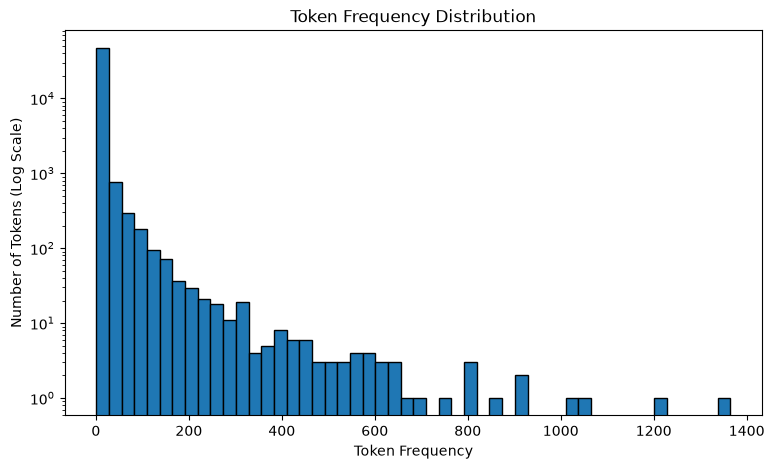

Total unique tokens: 48691
Average frequency: 5.687888932246206
Median frequency: 1.0
Most common tokens: [('new', 1365), ('date', 1202), ('get', 1052), ('please', 1022), ('enron', 927), ('like', 923), ('2002', 869), ('would', 806), ('one', 798), ('message', 795)]

Q2 Regression Results
Training R2: 0.7670143724934355
Testing R2: 0.6658718438847919
Testing MSE: 0.08066066087412473
Top 10 strongest words:
intervention        -1.259257
localized            0.824350
thermal              0.747006
crawler              0.696167
background-image:   -0.622909
helvetica,           0.598560
aging                0.594956
form.                0.576886
gray;               -0.574480
a:active             0.574480
dtype: float64


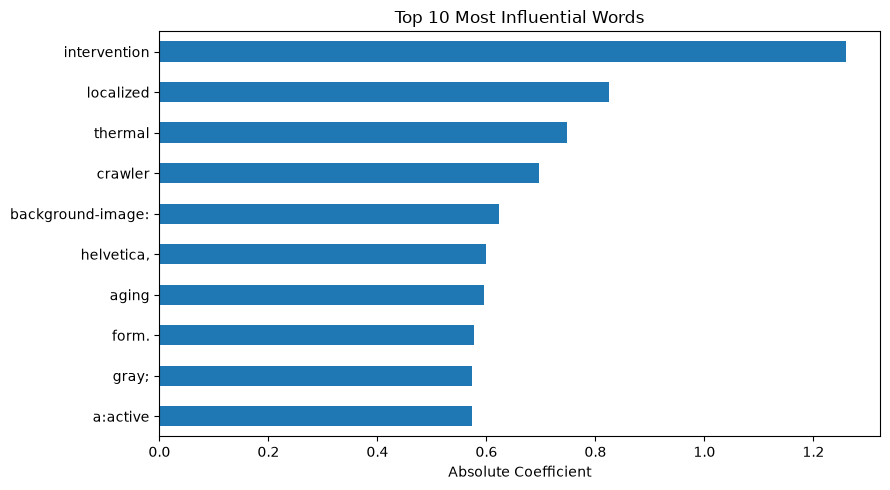

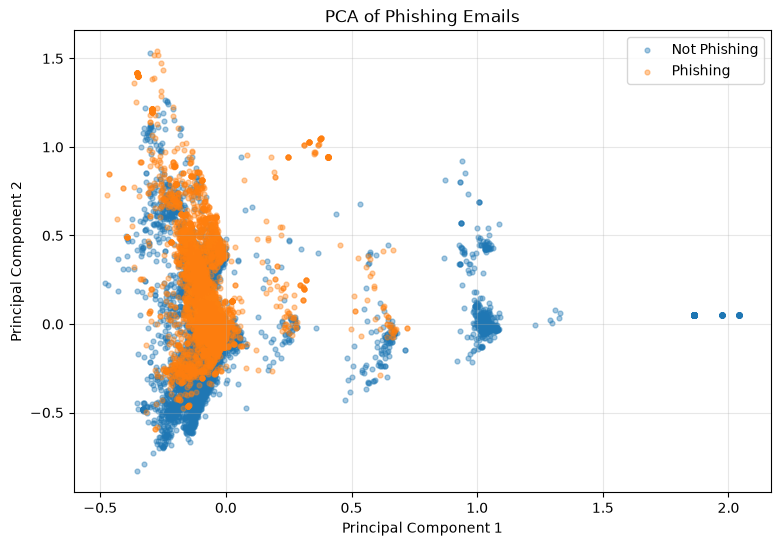

PC1 Variance: 0.011130883678032538
PC2 Variance: 0.008611749192658294
Total Variance: 0.01974263287069083


In [ ]:

# Phase 2 - Improved Solutions

import pandas as pd
import numpy as np
import pickle
import matplotlib.pyplot as plt
from collections import Counter
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.decomposition import PCA
from sklearn.metrics import mean_squared_error

# Q1: Token Frequency Distribution

with open("data/all_tokens.pickle", "rb") as file:
    all_tokens = pickle.load(file)

token_count = Counter(all_tokens)
frequencies = list(token_count.values())

plt.figure(figsize=(9, 5))
plt.hist(frequencies, bins=50, edgecolor="black")
plt.yscale("log")
plt.xlabel("Token Frequency")
plt.ylabel("Number of Tokens (Log Scale)")
plt.title("Token Frequency Distribution")
plt.show()

print("Total unique tokens:", len(token_count))
print("Average frequency:", np.mean(frequencies))
print("Median frequency:", np.median(frequencies))
print("Most common tokens:", token_count.most_common(10))


# Q2: Linear Regression

df = pd.read_parquet("data/Phishing_clean.parquet")

X = df.drop(columns=["Email Type"])
y = df["Email Type"]

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)

model = LinearRegression()
model.fit(X_train, y_train)

print("\nQ2 Regression Results")
print("Training R2:", model.score(X_train, y_train))
print("Testing R2:", model.score(X_test, y_test))
print("Testing MSE:", mean_squared_error(
    y_test, model.predict(X_test)
))

coefficients = pd.Series(model.coef_, index=X.columns)
top_words = coefficients.abs().nlargest(10)

print("Top 10 strongest words:")
print(coefficients.loc[top_words.index])

plt.figure(figsize=(9, 5))
top_words.sort_values().plot(kind="barh")
plt.xlabel("Absolute Coefficient")
plt.title("Top 10 Most Influential Words")
plt.tight_layout()
plt.show()


# Q3: PCA with 2 Components

pca2 = PCA(n_components=2)
X_pca2 = pca2.fit_transform(X)

plt.figure(figsize=(9, 6))

plt.scatter(
    X_pca2[y == 0, 0],
    X_pca2[y == 0, 1],
    label="Not Phishing",
    alpha=0.4,
    s=12
)

plt.scatter(
    X_pca2[y == 1, 0],
    X_pca2[y == 1, 1],
    label="Phishing",
    alpha=0.4,
    s=12
)

plt.xlabel("Principal Component 1")
plt.ylabel("Principal Component 2")
plt.title("PCA of Phishing Emails")
plt.legend()
plt.grid(alpha=0.3)
plt.show()

print("PC1 Variance:", pca2.explained_variance_ratio_[0])
print("PC2 Variance:", pca2.explained_variance_ratio_[1])
print("Total Variance:", sum(pca2.explained_variance_ratio_))



                 Model  Training R2  Testing R2
0  Original Regression     0.767014    0.665872
1       PCA Regression     0.766179    0.668450


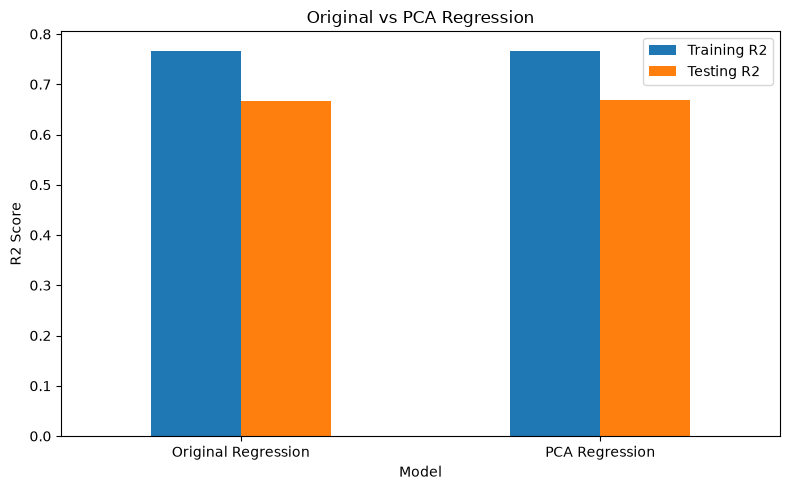

Difference in Testing R2: 0.0025779839689278328


In [ ]:
# Q4: Regression Using 2610 PCA Components

pca = PCA(
    n_components=2610,
    svd_solver="randomized",
    random_state=42
)

X_train_pca = pca.fit_transform(X_train)
X_test_pca = pca.transform(X_test)

pca_model = LinearRegression()
pca_model.fit(X_train_pca, y_train)

original_train = model.score(X_train, y_train)
original_test = model.score(X_test, y_test)

pca_train = pca_model.score(X_train_pca, y_train)
pca_test = pca_model.score(X_test_pca, y_test)

results = pd.DataFrame({
    "Model": ["Original Regression", "PCA Regression"],
    "Training R2": [original_train, pca_train],
    "Testing R2": [original_test, pca_test]
})

print(results)

results.set_index("Model").plot(
    kind="bar",
    figsize=(8, 5)
)

plt.ylabel("R2 Score")
plt.title("Original vs PCA Regression")
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

print("Difference in Testing R2:", pca_test - original_test)


**Q5: Advantages of PCA**

PCA is helpful when working with data that has a lot of variables. It combines information from the original variables into new components that are not correlated with each other. This makes it easier to work with large datasets and can reduce problems caused by highly related variables.

However, PCA does not always improve predictions because reducing the number of components can remove useful information.

### *Reflection on AI assistance
In your own words without generative AI.

AI helped me improve my original answers in a few different ways. First, it made my token frequency graph easier to understand by adding a log scale and more information. It also helped improve my regression by adding a graph showing the most important words. For PCA it made the scatter plot clearer and helped me compare the two regression models.

There were also some limitations with the AI suggestions. For example, the log scale made the graph look different. This was a little confusing at first. I also learned that PCA does not always make a model more accurate because some useful information can be lost.

To check the AI's work I looked at the code and compared the changes with my original solutions. I also checked the graphs and the R2 scores to see if the results made sense. This helped me better understand what the code was actually doing.

One concern I still have is that the regression models might not perform as well on new data. Overall, AI helped me improve my work and made the results easier to understand.